# Minimal DeepCluster on CIFAR-10

Compare **RGB vs. Sobel** inputs and different cluster counts `K` using ResNet-18.

- CIFAR-10 is downloaded directly with `torchvision.datasets.CIFAR10`.
- DeepCluster alternates between K-means pseudo-label assignment and network training.
- Evaluation: NMI (cluster assignments vs. train labels) and linear-probe Top-1 accuracy.
- W&B is optional. Start with `USE_WANDB = False`.

In [19]:
# If needed, uncomment:
# %pip install -q torch torchvision scikit-learn wandb

import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms, models
from sklearn.cluster import KMeans
from sklearn.metrics import normalized_mutual_info_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

SEED = 42
IMAGE_SIZE = 32
BATCH_SIZE = 
EPOCHS = 10
K_VALUES = [10, 20]
MODES = ["rgb", "sobel"]
NUM_WORKERS = 2
USE_WANDB = True
WANDB_PROJECT = "deepcluster-cifar10"

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


## CIFAR-10 and input transforms

In [8]:
!wget -P ./data/  https://data.brainchip.com/dataset-mirror/cifar10/cifar-10-python.tar.gz
!tar -xzf ./data/cifar-10-python.tar.gz -C ./dataset/
import tarfile
DATA_DIR = './data'
with tarfile.open('./data/cifar-10-python.tar.gz') as tf:
     tf.extractall(DATA_DIR)
     _found = [DATA_DIR]   # skip download
print("DATA_DIR:", DATA_DIR, "| using local files:", bool(_found))

--2026-10-28 17:06:41--  https://data.brainchip.com/dataset-mirror/cifar10/cifar-10-python.tar.gz
Resolving data.brainchip.com (data.brainchip.com)... 146.59.209.152, 2001:41d0:301::31
Connecting to data.brainchip.com (data.brainchip.com)|146.59.209.152|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 170498071 (163M) [application/x-gzip]
Saving to: ‘./data/cifar-10-python.tar.gz.3’

cifar-10-python.tar 100%[===================>] 162.60M  22.0MB/s    in 8.3s    

2026-10-28 17:06:50 (19.5 MB/s) - ‘./data/cifar-10-python.tar.gz.3’ saved [170498071/170498071]



/tmp/ipykernel_49/2114737339.py:6: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tf.extractall(DATA_DIR)


DATA_DIR: ./data | using local files: True


In [20]:
class InputTransform:
    def __init__(self, mode="rgb", train=False):
        self.mode = mode
        self.train = train
        self.augment = transforms.Compose([
            transforms.RandomResizedCrop(IMAGE_SIZE, scale=(0.7, 1.0)),
            transforms.RandomHorizontalFlip(),
        ]) if train else transforms.Resize((IMAGE_SIZE, IMAGE_SIZE))
        self.to_tensor = transforms.ToTensor()
        self.normalize = transforms.Normalize(
            mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)
        )

    def __call__(self, image):
        x = self.to_tensor(self.augment(image))
        if self.mode == "sobel":
            gray = (0.2989*x[0] + 0.5870*x[1] + 0.1140*x[2])[None, None]
            kx = x.new_tensor([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]]).view(1, 1, 3, 3)
            ky = x.new_tensor([[-1, -2, -1], [0, 0, 0], [1, 2, 1]]).view(1, 1, 3, 3)
            gx = F.conv2d(gray, kx, padding=1)
            gy = F.conv2d(gray, ky, padding=1)
            x = (torch.sqrt(gx.square() + gy.square() + 1e-12) / 4.0).clamp(0, 1)[0]
        return self.normalize(x)


class IndexedCIFAR10(Dataset):
    def __init__(self, base, mode, train):
        self.base = base
        self.transform = InputTransform(mode, train)

    def __len__(self):
        return len(self.base)

    def __getitem__(self, idx):
        image, label = self.base.data[idx], self.base.targets[idx]
        from PIL import Image
        image = Image.fromarray(image)
        return self.transform(image), idx, label


train_base = datasets.CIFAR10(root="./data/", train=True, download=False)
test_base = datasets.CIFAR10(root="./data/", train=False, download=False)
y_train = np.asarray(train_base.targets)
y_test = np.asarray(test_base.targets)
NUM_CLASSES = 10

def make_loader(base, mode, train=False, shuffle=False):
    ds = IndexedCIFAR10(base, mode, train)
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=shuffle,
                      num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"))

print("CIFAR-10:", len(train_base), "train images,", len(test_base), "test images")

CIFAR-10: 50000 train images, 10000 test images


In [12]:
import wandb
if USE_WANDB:
    try:
        from kaggle_secrets import UserSecretsClient
        key = UserSecretsClient().get_secret("WANDB_API_KEY")
        wandb.login(key=key) if key else wandb.login()
    except Exception:
        wandb.login()

/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: shriramgolla (shriramgolla-iit-hyderabad) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


## Model, feature extraction, and evaluation

In [35]:
FEATURE_DIM = 512

def build_model(k):
    weights = models.ResNet18_Weights.DEFAULT
    encoder = models.resnet18(weights=None)
    encoder.layer4[0] = nn.Conv2d(256, 512, kernel_size=3, stride=1, padding=1, bias=False)
    encoder.fc = nn.Identity()

    class DeepClusterModel(nn.Module):
        def __init__(self):
            super().__init__()
            self.encoder = encoder
            self.cluster_head = nn.Linear(FEATURE_DIM, k)

        def forward(self, x):
            return self.cluster_head(self.encoder(x))

    return DeepClusterModel().to(device)


@torch.no_grad()
def extract_features(model, loader):
    model.eval()
    features = np.zeros((len(loader.dataset), FEATURE_DIM), dtype=np.float32)
    labels = np.zeros(len(loader.dataset), dtype=np.int64)
    for x, idx, y in loader:
        z = model.encoder(x.to(device)).cpu().numpy()
        features[idx.numpy()] = z
        labels[idx.numpy()] = y.numpy()
    return features, labels


def cluster_features(features, k):
    x = (features - features.mean(0)) / (features.std(0) + 1e-6)
    return KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(x)


def linear_probe(train_features, test_features):
    scaler = StandardScaler()
    x_train = scaler.fit_transform(train_features)
    x_test = scaler.transform(test_features)
    clf = LogisticRegression(max_iter=1000, random_state=SEED)
    clf.fit(x_train, y_train)
    return clf.score(x_test, y_test)

## Train and compare RGB vs. Sobel

In [36]:
import wandb
import torch
import torch.nn.functional as F
import pandas as pd
from sklearn.metrics import normalized_mutual_info_score

results = []

for mode in MODES:
    for k in K_VALUES:
        run_name = f"{mode}-k{k}"
        print(f"\n--- mode={mode}, K={k} ---")

        # Initialize W&B once per experiment
        run = None
        if USE_WANDB:
            run = wandb.init(
                project=WANDB_PROJECT,
                name=run_name,
                group=f"deepcluster-{mode}",
                config={
                    "mode": mode,
                    "K": k,
                    "epochs": EPOCHS,
                    "seed": SEED,
                    "optimizer": "SGD",
                    "learning_rate": 0.03,
                    "momentum": 0.9,
                    "weight_decay": 1e-5,
                    "method": "DeepCluster",
                },
                reinit=True,
            )

        try:
            # Deterministic views for clustering/evaluation;
            # augmented views for training.
            train_eval_loader = make_loader( train_base, mode, train=False, shuffle=False )
            train_loader = make_loader( train_base, mode, train=True, shuffle=True)
            test_loader = make_loader(test_base, mode, train=False, shuffle=False )

            model = build_model(k)
            optimizer = torch.optim.SGD( model.parameters(), lr=0.03,momentum=0.9,weight_decay=1e-5, )

            for epoch in range(EPOCHS):
                # Recompute pseudo-labels from current features.
                train_features, labels_seen = extract_features( model, train_eval_loader)
                assignments = cluster_features(train_features, k)
                model.train()
                total_loss, total = 0.0, 0

                for x, idx, _ in train_loader:
                    x = x.to(device)
                    target = torch.as_tensor(assignments[idx.numpy()],dtype=torch.long, device=device)
                    optimizer.zero_grad(set_to_none=True)
                    loss = F.cross_entropy(model(x), target)
                    loss.backward()
                    optimizer.step()
                    total_loss += loss.item() * len(x)
                    total += len(x)

                epoch_loss = total_loss / total
                print( f"Epoch {epoch + 1:02d}/{EPOCHS} " f"| loss={epoch_loss:.4f}")
                # Log epoch-level metrics
                if run is not None:
                    wandb.log({
                        "epoch": epoch + 1,
                        "train/loss": epoch_loss,
                    }, step=epoch + 1)

            # Final feature extraction
            train_features, train_labels_seen = extract_features(
                model, train_eval_loader
            )
            test_features, test_labels_seen = extract_features(
                model, test_loader
            )

            final_assignments = cluster_features(train_features, k)

            row = {
                "mode": mode,
                "K": k,
                "NMI": normalized_mutual_info_score(
                    train_labels_seen, final_assignments
                ),
                "linear_probe_top1": linear_probe(
                    train_features, test_features
                ),
            }

            results.append(row)
            print(row)

            # Log final metrics to the same run
            if run is not None:
                wandb.log({
                    "final/NMI": row["NMI"],
                    "final/linear_probe_top1": row["linear_probe_top1"],
                    "final/epoch": EPOCHS,
                }, step=EPOCHS + 1)

                wandb.summary["final_NMI"] = row["NMI"]
                wandb.summary["final_linear_probe_top1"] = (
                    row["linear_probe_top1"]
                )

        finally:
            if run is not None:
                run.finish()

# Save results
results_df = pd.DataFrame(results)
display(results_df)

results_df.to_csv("deepcluster_cifar10_results.csv", index=False)
print("Saved deepcluster_cifar10_results.csv")


--- mode=rgb, K=10 ---


Epoch 01/10 | loss=0.8456
Epoch 02/10 | loss=0.6635
Epoch 03/10 | loss=0.6207
Epoch 04/10 | loss=0.6905
Epoch 05/10 | loss=0.6613
Epoch 06/10 | loss=0.6276
Epoch 07/10 | loss=0.7030
Epoch 08/10 | loss=0.5743
Epoch 09/10 | loss=0.6697
Epoch 10/10 | loss=0.6876
{'mode': 'rgb', 'K': 10, 'NMI': np.float64(0.04302177890514228), 'linear_probe_top1': 0.3085}


epoch,▁▂▃▃▄▅▆▆▇█
final/NMI,▁
final/epoch,▁
final/linear_probe_top1,▁
train/loss,█▃▂▄▃▂▄▁▃▄
epoch,10
final/NMI,0.04302
final/epoch,10
final/linear_probe_top1,0.3085
final_NMI,0.04302
final_linear_probe_top1,0.3085



--- mode=rgb, K=20 ---


Epoch 01/10 | loss=1.2145
Epoch 02/10 | loss=1.0315
Epoch 03/10 | loss=1.0257
Epoch 04/10 | loss=1.0219
Epoch 05/10 | loss=0.9520
Epoch 07/10 | loss=0.9972
Epoch 08/10 | loss=1.0475
Epoch 09/10 | loss=1.1959
Epoch 10/10 | loss=1.2634
{'mode': 'rgb', 'K': 20, 'NMI': np.float64(0.052486513303829835), 'linear_probe_top1': 0.3159}


...


--- mode=sobel, K=20 ---


Epoch 01/10 | loss=1.4280
Epoch 02/10 | loss=1.1761
Epoch 03/10 | loss=1.1901
Epoch 04/10 | loss=1.0760
Epoch 05/10 | loss=1.0086
Epoch 06/10 | loss=1.1270
Epoch 07/10 | loss=1.0974
Epoch 08/10 | loss=1.1106
Epoch 09/10 | loss=1.2152
Epoch 10/10 | loss=1.2203
{'mode': 'sobel', 'K': 20, 'NMI': np.float64(0.04889044493741065), 'linear_probe_top1': 0.3179}


epoch,▁▂▃▃▄▅▆▆▇█
final/NMI,▁
final/epoch,▁
final/linear_probe_top1,▁
train/loss,█▄▄▂▁▃▂▃▄▅
epoch,10
final/NMI,0.04889
final/epoch,10
final/linear_probe_top1,0.3179
final_NMI,0.04889
final_linear_probe_top1,0.3179


,mode,K,NMI,linear_probe_top1
0,rgb,10,0.043022,0.3085
1,rgb,20,0.052487,0.3159
2,sobel,10,0.012835,0.2803
3,sobel,20,0.048890,0.3179


Saved deepcluster_cifar10_results.csv


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

In [44]:
import matplotlib.pyplot as plt

In [55]:
model._modules['encoder'].conv1

Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)

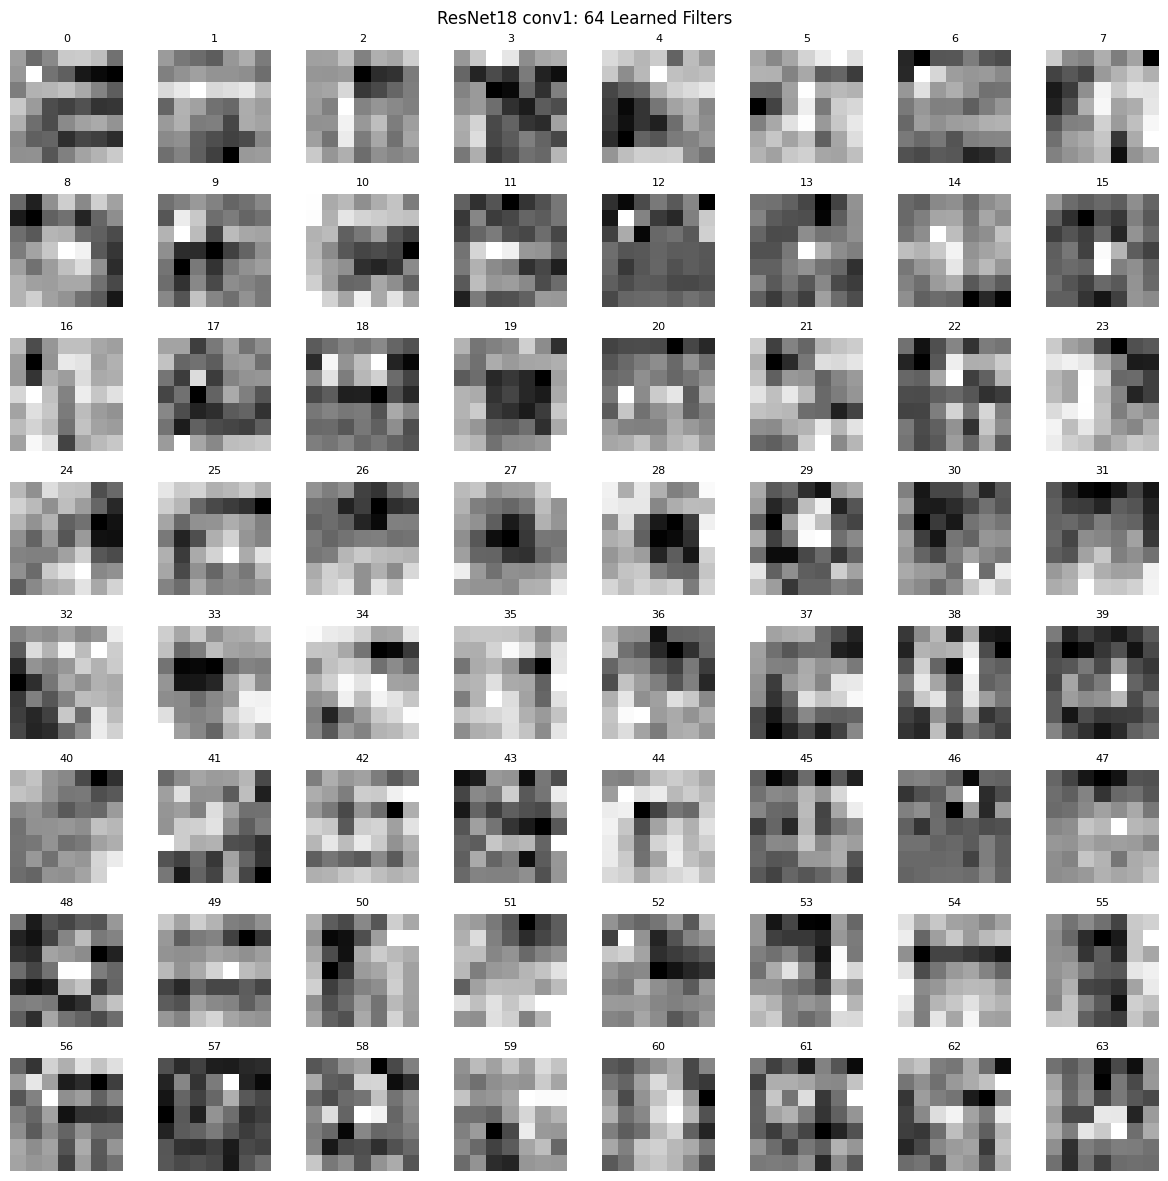

In [59]:
filters = model._modules['encoder'].conv1.weight.detach().cpu()

# Arrange 64 filters in an 8x8 grid
fig, axes = plt.subplots(8, 8, figsize=(12, 12))

for i, ax in enumerate(axes.flat):
    # [3, 7, 7] -> [7, 7, 3]
    f = filters[i].permute(1, 2, 0).numpy()[:,:,0]

    # Normalize each filter independently for visualization
    f_min, f_max = f.min(), f.max()
    f = (f - f_min) / (f_max - f_min + 1e-8)

    ax.imshow(f,cmap="gray")
    ax.axis("off")
    ax.set_title(str(i), fontsize=8)

plt.suptitle("ResNet18 conv1: 64 Learned Filters")
plt.tight_layout()
plt.show()
